# Chapitre 8 - Cours 4 : pauses de processus, majorité, baux et jetons de clôture

Un nœud qui détient un **bail** (un verrou à durée limitée) peut s'endormir au pire moment
et se réveiller sans savoir qu'il a dormi, alors que les autres l'ont déclaré mort et
ont donné son bail à un autre. Ce notebook montre pourquoi cela arrive, pourquoi un nœud
ne peut pas se fier à son propre jugement, et comment le **jeton de clôture** empêche un
tel « zombie » de corrompre les données. Il couvre la section *Process Pauses* (*Response time guarantees*,
*Limiting the impact of garbage collection*) et le début de *Knowledge, Truth, and Lies* :
*The Truth Is Defined by the Majority* (*The leader and the lock*, *Fencing tokens*).

**Plan.**

1. Le bail et la boucle naïve : un processus peut s'arrêter n'importe où.
2. Garanties de temps de réponse et ramasse-miettes.
3. La majorité fait loi.
4. Verrous et baux distribués : la corruption par un zombie.
5. Les jetons de clôture.

In [1]:
import os
import signal
import subprocess
import sys
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Network
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Le bail et la boucle naïve (section *Process Pauses*)

Dans une base où chaque partition a un leader unique, seul le leader
accepte les écritures. Comment un nœud sait-il qu'il est **encore** leader, que les
autres ne l'ont pas déclaré mort ? Une solution est le **bail** (lease) : un verrou
assorti d'une durée, accordé par les autres nœuds ou par un service de verrous. Tant que
le bail court, le nœud se sait leader ; il doit le **renouveler** avant expiration, et
s'il tombe, il cesse de le renouveler et un autre prend la relève. La boucle de
traitement ressemble à ceci (transcription en Python de l'exemple du livre) :

```python
while True:
    requete = attendre_requete()
    # garder au moins 10 secondes de marge sur le bail
    if bail.expiration - time.time() < 10:
        bail = bail.renouveler()
    if bail.est_valide():
        traiter(requete)          # <- et si le processus s'arrête juste avant ?
```

Deux défauts :

1. l'expiration a été fixée par **une autre machine** (son heure + 30 s) et on la compare
   à l'horloge **locale** : si les horloges divergent de quelques secondes, le code fait
   n'importe quoi (cours 3) ;
2. même avec une horloge monotone locale, le code suppose que **presque rien** ne se passe
   entre la vérification et le traitement. Si le fil d'exécution s'arrête 15 secondes
   juste après `est_valide()`, le bail a expiré quand la requête est traitée, un autre
   nœud est peut-être déjà leader, et rien ne prévient le fil qu'il a dormi.

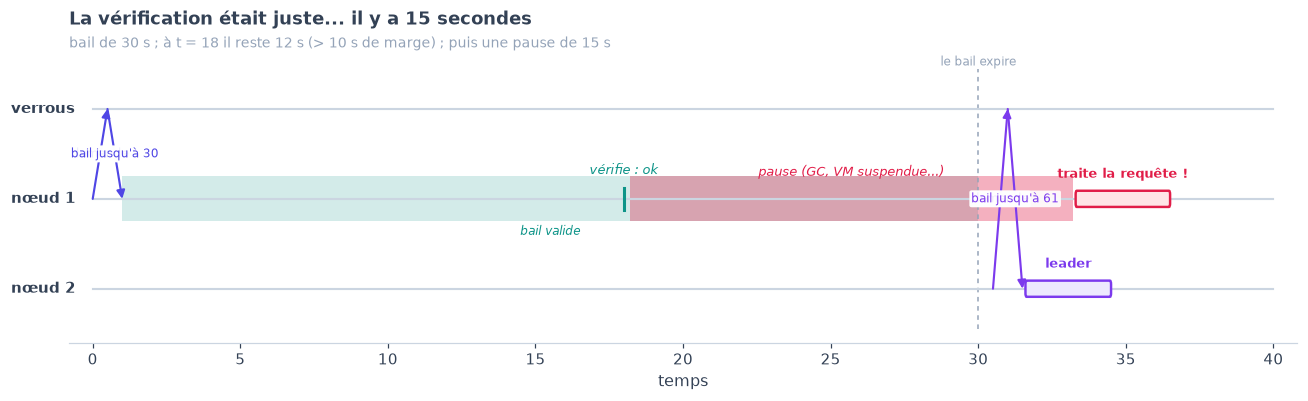

In [2]:
st = SpaceTime(["verrous", "nœud 1", "nœud 2"], t_max=40, width=12,
               title="La vérification était juste... il y a 15 secondes",
               subtitle="bail de 30 s ; à t = 18 il reste 12 s (> 10 s de marge) ; puis une pause de 15 s")
st.msg("nœud 1", 0.0, "verrous", 0.5, "demande", color=INDIGO)
st.msg("verrous", 0.5, "nœud 1", 1.0, "bail jusqu'à 30", color=INDIGO)
st.span("nœud 1", 1.0, 30.0, "bail valide", color=TEAL, alpha=0.18)
st.event("nœud 1", 18.0, "", kind="tick", color=TEAL)
st.note(18.0, "nœud 1", "vérifie : ok", dy=0.32, color=TEAL)
st.span("nœud 1", 18.2, 33.2, "", color=ROSE, alpha=0.35)
st.note(25.7, "nœud 1", "pause (GC, VM suspendue...)", dy=0.3, color=ROSE)
st.vline(30.0, "le bail expire")
st.msg("nœud 2", 30.5, "verrous", 31.0, "demande", color=VIOLET)
st.msg("verrous", 31.0, "nœud 2", 31.5, "bail jusqu'à 61", color=VIOLET)
st.op("nœud 2", 31.6, 34.5, "leader", color=VIOLET)
st.op("nœud 1", 33.3, 36.5, "traite la requête !", color=ROSE)
st.show()

**Est-il réaliste qu'un fil s'arrête aussi longtemps ?** Oui, pour bien des raisons :

| cause | durée typique |
|---|---|
| contention sur un verrou ou une file partagés | ms à s |
| ramasse-miettes « stop-the-world » (JVM...) | ms ; jadis jusqu'à plusieurs minutes |
| suspension puis reprise d'une machine virtuelle, migration à chaud | s à minutes |
| portable dont on ferme le couvercle, téléphone en veille | minutes à heures |
| commutation de contexte, temps volé par l'hyperviseur (steal time) sous forte charge | ms à s |
| E/S disque synchrones (y compris un chargement de classe paresseux, un disque réseau) | ms à s |
| défaut de page, échange avec le disque (swap), voire écroulement (thrashing) | ms à minutes |
| signal `SIGSTOP` (Ctrl-Z), envoyé exprès ou par erreur | illimitée |

Le dernier cas se reproduit facilement. Lançons un petit processus qui, toutes les 10
ms, note l'heure de son horloge monotone ; pendant qu'il tourne, on lui envoie `SIGSTOP`,
puis `SIGCONT` une seconde plus tard.

In [3]:
code = textwrap.dedent("""
    import time, sys
    t0 = last = time.monotonic(); trous = []
    while time.monotonic() - t0 < 2.0:
        time.sleep(0.01)
        now = time.monotonic()
        if now - last > 0.05:
            trous.append((round(last - t0, 3), round(now - last, 3)))
        last = now
    print(trous)
""")
p = subprocess.Popen([sys.executable, "-c", code], stdout=subprocess.PIPE, text=True)
time.sleep(0.4)
os.kill(p.pid, signal.SIGSTOP)
time.sleep(1.0)
os.kill(p.pid, signal.SIGCONT)
out, _ = p.communicate(timeout=10)
trous = eval(out)
print("trous observés par le processus (début, durée en s) :", trous)

trous observés par le processus (début, durée en s) : [(0.382, 1.006)]


Le processus n'a rien vu sur le moment : il a simplement constaté, **après coup** et
seulement parce qu'il relisait son horloge, qu'une de ses itérations de 10 ms avait duré
une seconde. Un nœud d'un système distribué doit supposer que son exécution peut être
suspendue longtemps **à n'importe quel point**, même au milieu d'une fonction ; pendant
ce temps, le reste du monde avance et peut le déclarer mort.

Sur une seule machine, on a des outils pour le code concurrent (mutex, sémaphores,
compteurs atomiques, files bloquantes). Ils ne se transposent pas au distribué : il n'y
a **pas de mémoire partagée**, seulement des messages sur un réseau non fiable.

**Combien de temps peut durer une pause ?** Le module fournit un générateur de pauses
synthétiques (`ds.gc_pause_samples`) : surtout des petites collectes de quelques
millisecondes, et, deux fois sur mille, une longue pause à queue lourde (collecte
complète, échange de pages, suspension de VM).

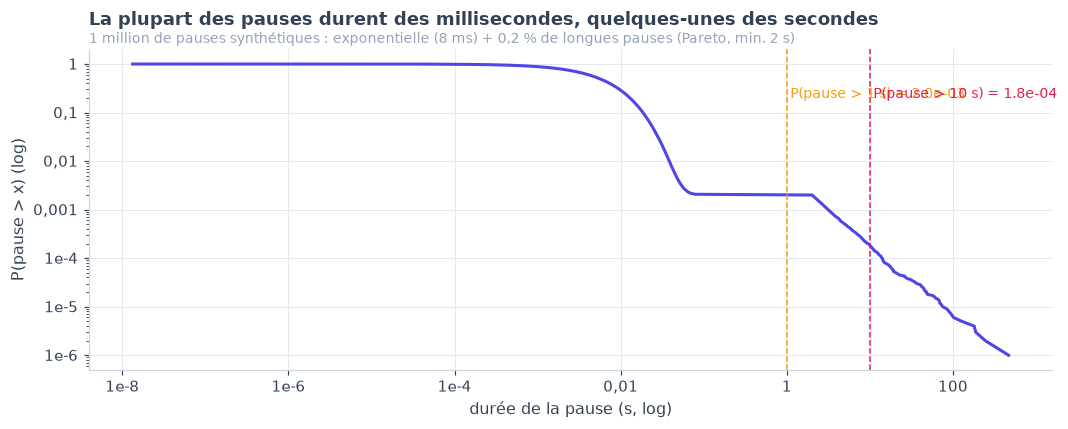

avec 10 pauses par seconde, pauses de plus de 10 s attendues par jour : 159


In [4]:
pauses = ds.gc_pause_samples(1_000_000, seed=1)
xs = np.sort(pauses)
idx = np.unique(np.r_[np.arange(0, xs.size, 400), xs.size - np.geomspace(1, xs.size // 2, 300).astype(int)])
fig, ax = plt.subplots(figsize=(10, 4))
ax.loglog(xs[idx], 1 - idx / xs.size, color=INDIGO)
for m, c in [(1, AMBER), (10, ROSE)]:
    pm = (pauses > m).mean()
    ax.axvline(m, color=c, ls="--", lw=1)
    ax.text(m * 1.1, 0.2, f"P(pause > {m} s) = {pm:.1e}", color=c, fontsize=9)
plain_log_axis(ax)
ax.set_xlabel("durée de la pause (s, log)"); ax.set_ylabel("P(pause > x) (log)")
ax.set_title("La plupart des pauses durent des millisecondes, quelques-unes des secondes")
subtitle(ax, "1 million de pauses synthétiques : exponentielle (8 ms) + 0,2 % de longues pauses (Pareto, min. 2 s)")
plt.tight_layout(); plt.show()
p10 = (pauses > 10).mean()
print(f"avec 10 pauses par seconde, pauses de plus de 10 s attendues par jour : {p10 * 10 * 86400:.0f}")

Une pause sur cinq mille environ dépasse 10 secondes, la marge de la boucle naïve. Avec
une dizaine de pauses par seconde, cela fait plus d'une centaine par jour : la marge ne
protège de rien, elle rend seulement le problème plus rare.

> **À retenir.** Un processus peut être suspendu à n'importe quel endroit de son code,
> pendant une durée non bornée, sans le savoir. Vérifier un bail puis agir n'est donc
> pas sûr, quelle que soit la marge.

## 2. Garanties de temps de réponse et ramasse-miettes (sections *Response time guarantees* et *Limiting the impact of garbage collection*)

Ces causes de pause **peuvent** être éliminées, si l'on y met le prix. Les logiciels qui
pilotent des avions, des fusées, des robots ou des voitures doivent répondre à leurs
capteurs dans un délai garanti : ce sont des systèmes **temps réel dur** (hard
real-time). On ne veut pas que le déclenchement d'un airbag attende la fin d'une collecte
de mémoire. Cela exige un système d'exploitation temps réel (qui garantit des tranches de
processeur), des bibliothèques qui documentent leur pire temps d'exécution, une
allocation dynamique restreinte voire interdite, et énormément de tests. C'est très
coûteux, limite les langages et outils utilisables, et ne rend pas le système plus
**rapide** (il privilégie la ponctualité au débit). Pour les systèmes de données côté
serveur, ce n'est généralement ni rentable ni approprié : ils subissent les pauses.

(« Temps réel » n'a pas ici le sens flou du web, où il désigne des données poussées vers
les clients sans contrainte stricte de délai, chapitre 11.)

**Limiter l'effet du ramasse-miettes.** Les collecteurs modernes, bien réglés, ne
s'arrêtent plus que quelques millisecondes. On peut aussi réutiliser des objets (pools),
allouer hors du tas, ou traiter une collecte comme une **courte panne planifiée** : si le
runtime prévient qu'une collecte approche, on cesse d'envoyer des requêtes au nœud, on le
laisse finir celles en cours, puis il collecte pendant que les autres servent. Variante :
ne collecter que les objets à courte durée de vie et **redémarrer** périodiquement les
processus avant qu'une collecte complète ne soit nécessaire, un nœud à la fois comme
dans une mise à jour progressive. Simulons la première idée : 8 nœuds qui s'arrêtent
250 ms toutes les 10 s, avec un répartiteur aveugle ou prévenu des collectes.

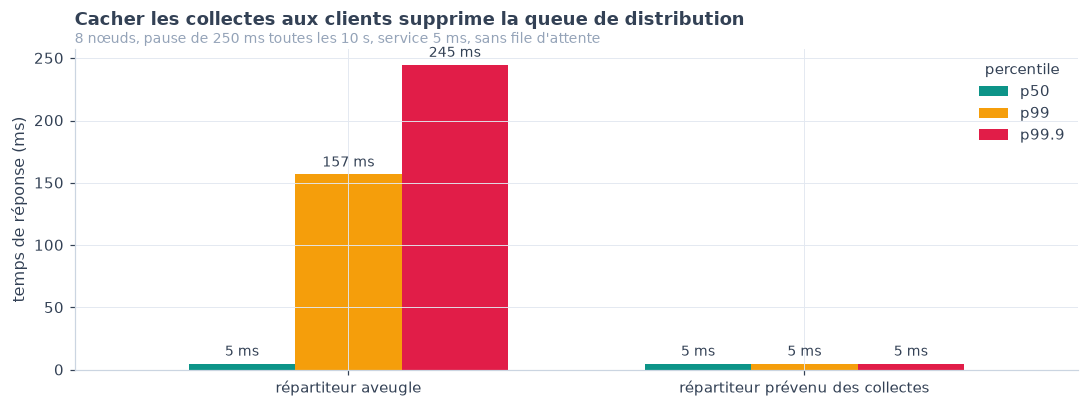

,p50,p99,p99.9
répartiteur aveugle,5.0,156.8,244.8
répartiteur prévenu des collectes,5.0,5.0,5.0


In [5]:
res = {}
for aware, nom in [(False, "répartiteur aveugle"), (True, "répartiteur prévenu des collectes")]:
    r = ds.gc_aware_routing(aware=aware, n_requests=200_000, seed=2) * 1e3
    res[nom] = {q: np.percentile(r, float(q[1:])) for q in ("p50", "p99", "p99.9")}
G = pd.DataFrame(res).T
ax = G.plot.bar(rot=0, color=[TEAL, AMBER, ROSE], figsize=(10, 3.8), width=0.7)
annotate_bars(ax, "{:.0f} ms", fontsize=9)
ax.set_ylabel("temps de réponse (ms)"); ax.set_xlabel("")
ax.set_title("Cacher les collectes aux clients supprime la queue de distribution")
subtitle(ax, "8 nœuds, pause de 250 ms toutes les 10 s, service 5 ms, sans file d'attente")
ax.legend(title="percentile")
plt.tight_layout(); plt.show()
G.round(1)

Une requête sur quarante tombe sur un nœud en pause (250 ms sur 10 s) : le p99 et le
p99.9 du répartiteur aveugle se comptent en centaines de millisecondes, alors que la
médiane vaut 5 ms. Prévenu, le répartiteur évite les nœuds qui collectent et tous les
percentiles retombent à 5 ms. Ces mesures **réduisent** l'effet des pauses mais ne les
**empêchent** pas : le problème du bail reste entier.

> **À retenir.** Des garanties de temps de réponse exigent un système temps réel dur,
> hors de prix pour un serveur de données. On peut atténuer les pauses (collecteurs
> modernes, collectes planifiées, redémarrages), pas les exclure.

## 3. La majorité fait loi (section *The Truth Is Defined by the Majority*)

Un nœud ne peut rien savoir **avec certitude** des autres : il n'a que les messages qu'il
reçoit, ou ne reçoit pas. Le livre raconte trois cauchemars :

1. **Faute asymétrique** : un nœud reçoit tout mais ses messages sortants se perdent. Les
   autres, qui ne l'entendent plus, le déclarent mort ; il crie « je ne suis pas mort ! »
   mais personne ne l'entend, et le cortège funèbre continue.
2. Variante : le nœud remarque que ses messages ne sont pas acquittés et comprend qu'il y
   a une panne réseau, mais il est déclaré mort quand même et n'y peut rien.
3. **Pause** : le nœud s'arrête une minute ; les autres le déclarent mort ; puis il se
   réveille comme si de rien n'était et se remet à bavarder, sans même savoir qu'une
   minute s'est écoulée.

Morale : un nœud **ne peut pas se fier à son propre jugement**, et un système ne peut pas
dépendre d'un seul nœud. Les décisions, y compris déclarer un nœud mort, se prennent par
**quorum** : un vote qui exige un nombre minimal de voix. Si un quorum déclare un nœud
mort, il **est** mort, même s'il se sent très vivant, et il doit se retirer. Rejouons les
cauchemars 1 et 3 avec trois membres (`ds.HeartbeatMember` : battements toutes les unités
de temps, suspicion après 3,5 unités de silence, déclaration de décès à la majorité).

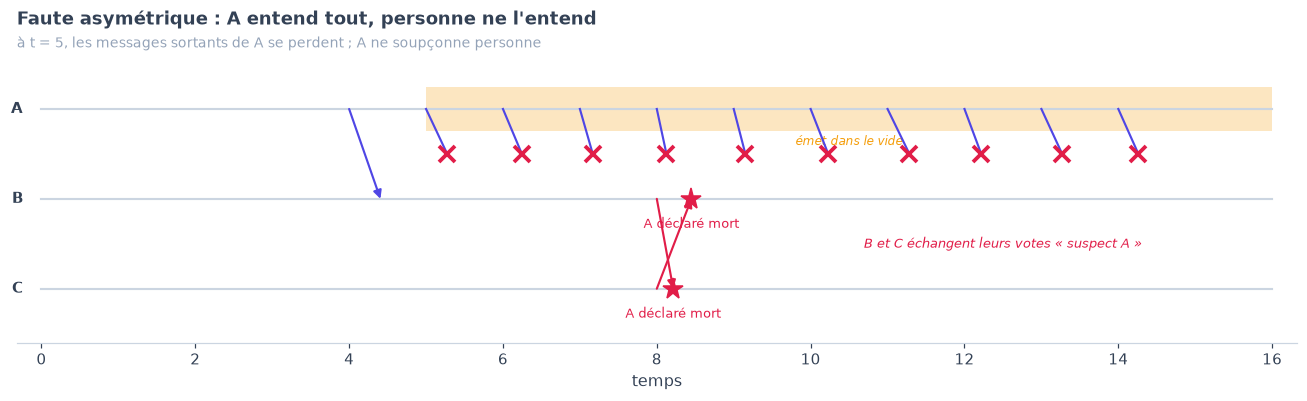

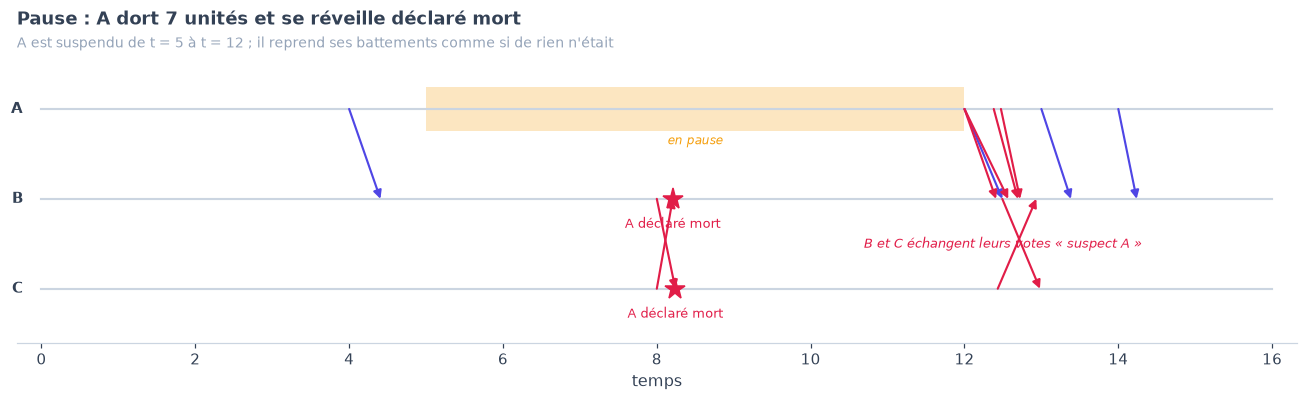

In [6]:
def cauchemar(kind):
    net = Network(seed=2, latency=(0.2, 0.6))
    grp = ["A", "B", "C"]
    nodes = {g: net.add(ds.HeartbeatMember(g, grp, interval=1.0, timeout=3.5)) for g in grp}
    if kind == "asym":
        net.at(5.0, net.block, "A", "B"); net.at(5.0, net.block, "A", "C")
    else:
        net.at(5.0, net.crash, "A"); net.at(12.0, net.recover, "A")
    net.run(until=16)
    return net, nodes

for kind, titre, sub in [("asym", "Faute asymétrique : A entend tout, personne ne l'entend",
                          "à t = 5, les messages sortants de A se perdent ; A ne soupçonne personne"),
                         ("pause", "Pause : A dort 7 unités et se réveille déclaré mort",
                          "A est suspendu de t = 5 à t = 12 ; il reprend ses battements comme si de rien n'était")]:
    net, nodes = cauchemar(kind)
    st = SpaceTime(["A", "B", "C"], t_max=16, width=12, title=titre, subtitle=sub)
    st.from_trace([d for d in net.trace if (d.src == "A" and d.dst == "B" and 3 < d.t_send < 15)
                   or (d.msg[0] == "suspect" and {d.src, d.dst} == {"B", "C"})],
                  color_of=lambda d: ROSE if d.msg[0] == "suspect" else INDIGO)
    st.note(12.5, "B", "B et C échangent leurs votes « suspect A »", dy=-0.5, color=ROSE)
    if kind == "asym":
        st.span("A", 5.0, 16, "émet dans le vide", color=AMBER)
    else:
        st.span("A", 5.0, 12.0, "en pause", color=AMBER)
    for g in ("B", "C"):
        if "A" in nodes[g].declared:
            st.event(g, nodes[g].declared["A"], "A déclaré mort", kind="star", color=ROSE)
    st.show()

Dans les deux cas, B et C ne reçoivent plus rien de A, le soupçonnent, échangent leurs
votes et, à deux voix sur trois, le déclarent mort vers $t \approx 8$. Dans le premier
scénario, A n'a jamais cessé de fonctionner, et rien dans ce qu'il reçoit ne l'avertit de
son sort. Dans le second, A se réveille à $t = 12$ et reprend ses battements, sans savoir
que sa mort a été prononcée. Le système doit être conçu pour que A, dans ces situations,
ne puisse **pas** faire de dégâts (sections 4 et 5).

**Pourquoi la majorité ?** Le quorum le plus courant est la **majorité absolue** (plus de
la moitié des nœuds). Elle tolère la panne d'une minorité ($n = 2f + 1$ nœuds tolèrent
$f$ pannes) et elle est **sûre** : deux majorités ont toujours au moins un nœud en commun,
donc il ne peut pas exister deux majorités qui décident des choses contradictoires.
Vérifions-le par force brute, et calculons la probabilité qu'une majorité soit joignable
quand chaque nœud l'est avec une probabilité $a$.

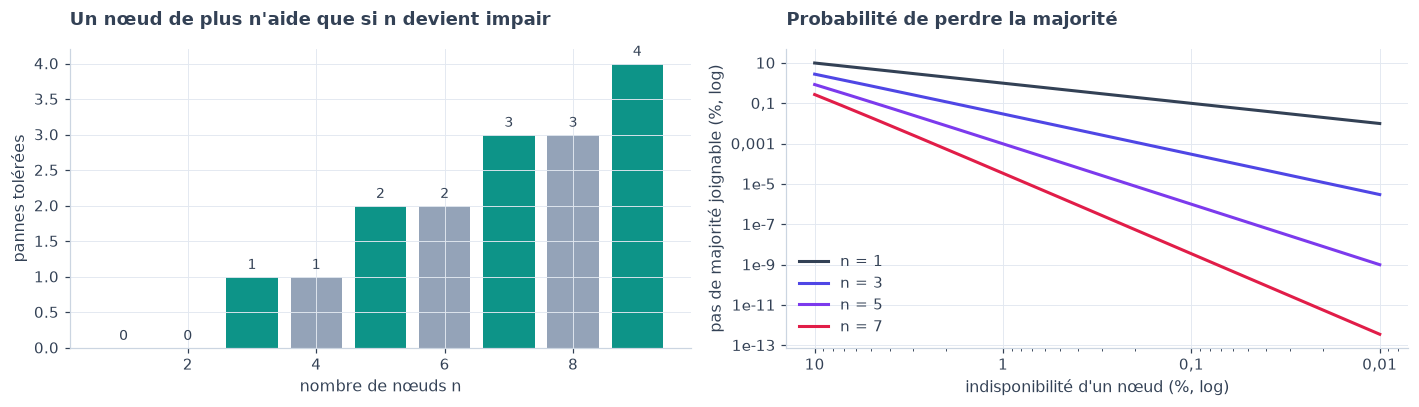

n,1,2,3,4,5,6,7,8,9
majorité,1,2,2,3,3,4,4,5,5
pannes_tolérées,0,0,1,1,2,2,3,3,4
majorités_se_recoupent,True,True,True,True,True,True,True,True,True


In [7]:
from math import comb
rows = []
for n in range(1, 10):
    rows.append(dict(n=n, majorité=n // 2 + 1, pannes_tolérées=ds.tolerated_faults(n),
                     majorités_se_recoupent=ds.majorities_intersect(n)))
Q = pd.DataFrame(rows).set_index("n")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.bar(Q.index, Q.pannes_tolérées, color=[TEAL if n % 2 else GRAY for n in Q.index])
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre de nœuds n"); ax.set_ylabel("pannes tolérées")
ax.set_title("Un nœud de plus n'aide que si n devient impair")
ax = axes[1]
a = np.linspace(0.9, 0.9999, 200)
for n, c in [(1, SLATE), (3, INDIGO), (5, VIOLET), (7, ROSE)]:
    q = n // 2 + 1
    avail = sum(comb(n, k) * a ** k * (1 - a) ** (n - k) for k in range(q, n + 1))
    ax.plot((1 - a) * 100, (1 - avail) * 100, color=c, label=f"n = {n}")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax); ax.invert_xaxis()
ax.set_xlabel("indisponibilité d'un nœud (%, log)"); ax.set_ylabel("pas de majorité joignable (%, log)")
ax.set_title("Probabilité de perdre la majorité")
ax.legend()
plt.tight_layout(); plt.show()
Q.T

Toutes les paires de majorités se recoupent, pour tout $n$ testé. Avec 4 nœuds, la
majorité est 3 et l'on ne tolère qu'une panne, comme avec 3 : c'est pourquoi les clusters
de consensus ont un nombre impair de nœuds. Le chapitre 9 utilisera ces
quorums dans les algorithmes de consensus.

> **À retenir.** Un nœud peut être déclaré mort à tort sans le savoir ; il ne peut pas se
> fier à son propre jugement. Les décisions se prennent par quorum, généralement une
> majorité, qui tolère la panne d'une minorité et ne peut pas être dupliquée.